# Delivery-Time Regression: Ensemble Comparison

**Retain HGB as the final regression model.** The current three-model stack gives **100% weight to HGB and zero to Ridge and RF in every fold**, reproducing HGB exactly. The HGB/ExtraTrees weighted combination has the lowest observed MAE, but its improvement is only about **1.93 minutes of average absolute error**.

The main comparison covers HGB, the **current Ridge + RF + HGB stack**, and the two HGB/ExtraTrees combinations. The current stack has one RF definition: **F1 + time/risk, log1p target**. It replaces the earlier original-target RF while retaining the existing inner-selected Ridge and audited HGB predictions. The appendix preserves all **14 unique random-split ensemble candidates** and the earlier RF specifications as historical evidence.

This notebook displays saved, independently verified aggregates from [nested tuning](../stacking/nested_tuning/README.md), the [ensemble follow-up](../stacking/ensemble_followup/README.md), and the [RF replacement](../stacking/rf_risk_upgrade/README.md). Execution checks all three packages' hashes and shared reference agreement; it does not fit models or evaluate the test set.


In [1]:
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

def formatted_table(frame, formats):
    """Format a display copy without pandas Styler's optional dependencies."""
    shown = frame.copy()
    if isinstance(formats, str):
        formats = {column: formats for column in shown.columns}
    for column, template in formats.items():
        shown[column] = shown[column].map(template.format)
    return shown

def locate_regression_root():
    for parent in [Path.cwd(), *Path.cwd().parents]:
        for candidate in [parent, parent / "Regression", parent / "Final Notebooks/Regression",
                          parent / "Phase 2/Final Notebooks/Regression"]:
            if (candidate / "stacking/nested_tuning/config/protocol.json").is_file():
                return candidate
    raise FileNotFoundError("Run from the project or a directory below Phase 2/Regression.")

REGRESSION = locate_regression_root()

def load_verified_package(name):
    root = REGRESSION / "stacking" / name
    results = root / "results"
    validation = json.loads((results / "validation.json").read_text())
    assert validation["status"] == "passed" and all(validation["checks"].values()), name
    for relative, expected in validation["public_artifact_sha256"].items():
        assert hashlib.sha256((results / relative).read_bytes()).hexdigest() == expected, (name, relative)
    summary = json.loads((results / "summary.json").read_text())
    protocol = json.loads((root / "config/protocol.json").read_text())
    actual_protocol_sha = hashlib.sha256((root / "config/protocol.json").read_bytes()).hexdigest()
    assert actual_protocol_sha == summary["protocol_sha256"] == validation["protocol_sha256"]
    verifier = {"nested_tuning": "verify_nested_tuning.py", "ensemble_followup": "verify_followup.py",
                "rf_risk_upgrade": "verify_rf_risk_upgrade.py"}[name]
    actual_verifier_sha = hashlib.sha256((root / "scripts" / verifier).read_bytes()).hexdigest()
    if actual_verifier_sha != validation["verifier_source_sha256"]:
        migration = json.loads((REGRESSION / "final_layout.json").read_text())["path_adapters"]
        adapter = migration[str((root / "scripts" / verifier).relative_to(REGRESSION))]
        assert adapter["before_sha256"] == validation["verifier_source_sha256"]
        assert adapter["after_sha256"] == actual_verifier_sha
    else:
        assert actual_verifier_sha == validation["verifier_source_sha256"]
    assert summary["train_n"] == protocol["train_n"] == validation["train_n"] == 64634
    assert summary["outer_folds"] == protocol["outer_folds"] == validation["outer_folds"] == 5
    assert summary["inner_folds"] == protocol["inner_folds"] == validation["inner_folds"] == 3
    assert summary["test_set_read_or_scored"] is False and summary["deployment_refit"] is False
    tables = {path.stem: pd.read_csv(path) for path in (results / "tables").glob("*.csv")
              if f"tables/{path.name}" in validation["public_artifact_sha256"]}
    assert tables["comparison"].model.is_unique
    assert tables["comparison"].n.eq(summary["train_n"]).all()
    assert tables["comparison"].outer_folds.eq(summary["outer_folds"]).all()
    return {"root": root, "summary": summary, "protocol": protocol,
            "validation": validation, "tables": tables}

nested = load_verified_package("nested_tuning")
followup = load_verified_package("ensemble_followup")
upgrade = load_verified_package("rf_risk_upgrade")
nc = nested["tables"]["comparison"].set_index("model")
fc = followup["tables"]["comparison"].set_index("model")
uc = upgrade["tables"]["comparison"].set_index("model")
nf = nested["tables"]["outer_fold_metrics"]
ff = followup["tables"]["outer_fold_metrics"]
uf = upgrade["tables"]["outer_fold_metrics"]
assert hashlib.sha256((nested["root"] / "results/validation.json").read_bytes()).hexdigest() == (
    followup["validation"]["reused_reference"]["previous_validation_sha256"])
for name, package in [("nested_tuning", nested), ("ensemble_followup", followup)]:
    assert hashlib.sha256((package["root"] / "results/validation.json").read_bytes()).hexdigest() == (
        upgrade["summary"]["reference_validation_sha256"][name])

# References recur across source packages, but are counted only once in this report.
shared_metrics = ["n", "outer_folds", "mean_fold_MAE_days", "fold_MAE_SD_days", "mean_fold_RMSE_days",
                  "pooled_MAE_days", "MAE_change_vs_HGB_days"]
def assert_reference_agreement(left_comparison, left_folds, old, right_comparison, right_folds, reused):
    np.testing.assert_allclose(left_comparison.loc[old, shared_metrics].astype(float),
                               right_comparison.loc[reused, shared_metrics].astype(float), rtol=0, atol=1e-12)
    left = left_folds.loc[left_folds.model.eq(old)].set_index("outer_fold").sort_index()
    right = right_folds.loc[right_folds.model.eq(reused)].set_index("outer_fold").sort_index()
    np.testing.assert_array_equal(left.index, right.index)
    numeric = left.select_dtypes(include="number").columns.intersection(right.columns)
    np.testing.assert_allclose(left[numeric], right[numeric], rtol=0, atol=1e-12)

for old, reused in [("hgb", "hgb"), ("stack_three_tuned", "previous_stack")]:
    assert_reference_agreement(nc, nf, old, fc, ff, reused)
for old, reused in [("hgb", "hgb"), ("stack_three_tuned", "previous_stack"),
                    ("ridge_tuned", "ridge_tuned"), ("forest_tuned", "previous_rf")]:
    assert_reference_agreement(nc, nf, old, uc, uf, reused)
assert_reference_agreement(fc, ff, "stack_hgb_extra_trees", uc, uf, "extra_trees_stack")

nested_ids = [f"{method}_{size}_{setting}" for setting in ["fixed", "tuned"]
              for size in ["two", "three"] for method in ["mean", "stack"]]
followup_ids = [f"{method}_hgb_{family}" for family in ["rf_log", "extra_trees"]
               for method in ["mean", "stack"]]
upgrade_ids = ["mean_three_rf_risk", "stack_three_rf_risk"]
ensembles = pd.concat([nc.loc[nested_ids], fc.loc[followup_ids], uc.loc[upgrade_ids]])
assert len(nested_ids) == 8 and len(followup_ids) == 4 and len(upgrade_ids) == 2
assert len(ensembles) == ensembles.index.nunique() == 14
assert "hgb" not in ensembles.index and "previous_stack" not in ensembles.index
assert set(nc.index[nc.index.str.startswith(("mean_", "stack_"))]) == set(nested_ids)
assert set(fc.index[fc.index.str.startswith(("mean_", "stack_"))]) == set(followup_ids)
assert set(uc.index[uc.index.str.startswith(("mean_", "stack_"))]) == set(upgrade_ids)

outer_folds = followup["summary"]["outer_folds"]
current = pd.concat([fc.loc[["hgb", "mean_hgb_extra_trees", "stack_hgb_extra_trees"]],
                     uc.loc[["stack_three_rf_risk"]]])
main_ids = ["hgb", "stack_three_rf_risk", "mean_hgb_extra_trees", "stack_hgb_extra_trees"]
main_labels = ["HGB (final model)", "Ridge + RF time/risk + HGB: MAE-weighted", "HGB + ExtraTrees: 50/50",
               "HGB + ExtraTrees: MAE-weighted"]
fold_mae = uf.pivot(index="outer_fold", columns="model", values="MAE_days").sort_index()
fold_mae["stack_hgb_extra_trees"] = ff.loc[ff.model.eq("stack_hgb_extra_trees")].set_index("outer_fold").MAE_days
assert len(fold_mae) == outer_folds and not fold_mae.isna().any().any()
print(f"Verified: all three saved packages, protocol hashes, shared metrics/folds, and {len(ensembles)} unique ensembles.")
print(f"Training orders: {followup['summary']['train_n']:,} | Outer folds: {outer_folds} | "
      f"Inner folds: {followup['summary']['inner_folds']} | New test evaluation: False | Deployment refit: False")


Verified: all three saved packages, protocol hashes, shared metrics/folds, and 14 unique ensembles.
Training orders: 64,634 | Outer folds: 5 | Inner folds: 3 | New test evaluation: False | Deployment refit: False


## Main comparison

All errors are in days unless labelled otherwise; lower is better. Mean MAE gives equal weight to the five outer folds. Fold SD is sample SD (`ddof=1`); it describes variation, not a confidence interval. Negative MAE changes favor the ensemble.


In [2]:
main = current.loc[main_ids, ["mean_fold_MAE_days", "fold_MAE_SD_days", "mean_fold_RMSE_days"]].copy()
main["MAE change vs HGB (minutes)"] = (main.mean_fold_MAE_days - fc.loc["hgb", "mean_fold_MAE_days"]) * 1440
main.index = pd.Index(main_labels, name="Model")
main = main.rename(columns={"mean_fold_MAE_days": "Mean MAE (days)", "fold_MAE_SD_days": "Fold MAE SD",
                            "mean_fold_RMSE_days": "Mean RMSE (days)"})
display(formatted_table(main, {"Mean MAE (days)": "{:.6f}", "Fold MAE SD": "{:.4f}",
                           "Mean RMSE (days)": "{:.6f}", "MAE change vs HGB (minutes)": "{:+.2f}"}))
for name, label in [("stack_three_rf_risk", "Current three-model stack"),
                     ("stack_hgb_extra_trees", "HGB/ExtraTrees weighted combination")]:
    change = current.loc[name, "mean_fold_MAE_days"] - current.loc["hgb", "mean_fold_MAE_days"]
    fold_change = fold_mae[name] - fold_mae.hgb
    wins, ties = int((fold_change < -1e-10).sum()), int((fold_change.abs() <= 1e-10).sum())
    display(Markdown(f"**{label}:** MAE change versus HGB **{change:+.6f} days "
                     f"({change * 1440:+.2f} minutes; {change / current.loc['hgb', 'mean_fold_MAE_days'] * 100:+.3f}%)**. "
                     f"Across the {outer_folds} folds: **{wins} lower, {ties} tied, "
                     f"{outer_folds - wins - ties} higher MAE** (tie tolerance: 1e-10 days)."))
display(Markdown("Minute equivalents describe average absolute prediction error, not delivery-time savings. "
                 "Negative changes favor the combination. "
                 "These comparisons are retrospective development evidence; the five overlapping training folds "
                 "do not establish statistical significance or independent confirmation."))
current_stack_weights = upgrade["tables"]["weights"].query("model == 'stack_three_rf_risk'").pivot(
    index="outer_fold", columns="base_model", values="weight")
assert len(current_stack_weights) == outer_folds
assert current_stack_weights.ridge_tuned.eq(0).all() and current_stack_weights.rf_time_risk.eq(0).all()
assert current_stack_weights.hgb.eq(1).all()
np.testing.assert_allclose(fold_mae.stack_three_rf_risk, fold_mae.hgb, rtol=0, atol=1e-12)
display(Markdown(
    "**The current three-model stack reduces to HGB:** every outer partition assigns **0% to Ridge, "
    "0% to RF time/risk and 100% to HGB**. Improving RF's standalone MAE therefore produces "
    "no combination gain under this fitted weighting procedure. "
    "**Retain single HGB.** ExtraTrees gives the lowest observed combination MAE, but its small gain "
    "and lack of a final combination test evaluation do not justify replacing the retained model."))


,Mean MAE (days),Fold MAE SD,Mean RMSE (days),MAE change vs HGB (minutes)
Model,,,,
HGB (final model),4.237815,0.0369,7.745040,+0.00
Ridge + RF time/risk + HGB: MAE-weighted,4.237815,0.0369,7.745040,+0.00
HGB + ExtraTrees: 50/50,4.274538,0.0432,7.754110,+52.88
HGB + ExtraTrees: MAE-weighted,4.236474,0.0378,7.739784,-1.93


**Current three-model stack:** MAE change versus HGB **+0.000000 days (+0.00 minutes; +0.000%)**. Across the 5 folds: **0 lower, 5 tied, 0 higher MAE** (tie tolerance: 1e-10 days).

**HGB/ExtraTrees weighted combination:** MAE change versus HGB **-0.001342 days (-1.93 minutes; -0.032%)**. Across the 5 folds: **4 lower, 0 tied, 1 higher MAE** (tie tolerance: 1e-10 days).

Minute equivalents describe average absolute prediction error, not delivery-time savings. Negative changes favor the combination. These comparisons are retrospective development evidence; the five overlapping training folds do not establish statistical significance or independent confirmation.

**The current three-model stack reduces to HGB:** every outer partition assigns **0% to Ridge, 0% to RF time/risk and 100% to HGB**. Improving RF's standalone MAE therefore produces no combination gain under this fitted weighting procedure. **Retain single HGB.** ExtraTrees gives the lowest observed combination MAE, but its small gain and lack of a final combination test evaluation do not justify replacing the retained model.

## Current RF specification and controlled replacement

The current three-model stack uses **one fixed RF: the published RF + time/risk with a log target**. It fits `log1p(y)` with F1 inputs, fold-fitted time encoding and a learned risk probability, then returns `expm1` predictions floored at zero. Numeric inputs are not log-transformed. RF's direct regression inputs exclude HGB's expanded purchase block; the shared auxiliary risk classifier uses purchase attributes from that block, so its information can enter indirectly through the risk probability.

Only RF changes from the earlier tuned three-model stack. The matching inner-selected Ridge and audited HGB inner/outer predictions are reused. This is a controlled replacement of the full RF specification, changing both its target representation and risk input; it cannot isolate either change's individual effect. RF parameters are frozen, with **no new parameter search**.


In [3]:
rf_protocol = upgrade["protocol"]
rf_spec = rf_protocol["rf"]["specification"]
rf_params = {**rf_protocol["rf_defaults"], **rf_spec["params"]}
assert rf_spec["log_target"] is True and rf_spec["log_inputs"] is False
assert rf_spec["feature_pack"] == "F1" and rf_protocol["rf"]["pack"] == "time_risk"
display(Markdown(
    f"RF uses **{rf_params['n_estimators']} trees**, depth **{rf_params['max_depth']}**, "
    f"minimum leaf size **{rf_params['min_samples_leaf']}**, feature fraction **{rf_params['max_features']}**, "
    f"bootstrap fraction **{rf_params['max_samples']}**, and seed **{rf_params['random_state']}**. "
    "Time features are elapsed purchase days and year-month. The risk feature predicts the probability of duration exceeding 30 days."))
delta = uc.loc["stack_three_rf_risk", "mean_fold_MAE_days"] - uc.loc["previous_stack", "mean_fold_MAE_days"]
wins_previous = int((fold_mae.stack_three_rf_risk < fold_mae.previous_stack).sum())
display(Markdown(f"Standalone RF mean MAE changes from the historical **{uc.loc['previous_rf', 'mean_fold_MAE_days']:.6f}** "
                 f"to **{uc.loc['rf_time_risk', 'mean_fold_MAE_days']:.6f} days**. "
                 f"The previous three-model stack has MAE **{uc.loc['previous_stack', 'mean_fold_MAE_days']:.6f} days**. "
                 f"Replacing RF changes the stack's mean MAE by **{delta:+.6f} days "
                 f"({delta * 1440:+.2f} minutes)**, with lower MAE in **{wins_previous}/{outer_folds} folds**. "
                 "The previous rows remain historical comparators; they do not define additional current RF choices."))


RF uses **100 trees**, depth **24**, minimum leaf size **10**, feature fraction **0.8**, bootstrap fraction **0.8**, and seed **33**. Time features are elapsed purchase days and year-month. The risk feature predicts the probability of duration exceeding 30 days.

Standalone RF mean MAE changes from the historical **4.600224** to **4.415217 days**. The previous three-model stack has MAE **4.237396 days**. Replacing RF changes the stack's mean MAE by **+0.000419 days (+0.60 minutes)**, with lower MAE in **0/5 folds**. The previous rows remain historical comparators; they do not define additional current RF choices.

## Why test ExtraTrees?

ExtraTrees averages many randomized decision trees. Its random split thresholds can produce different errors from HGB's sequential boosting, which motivates testing whether a small ExtraTrees contribution improves HGB. Complementary errors are a hypothesis to evaluate, not a guarantee that averaging helps.

The bounded search compares only **two target representations**, with identical tree settings and F1 plus time inputs. F1 contains calendar and interaction features; the time block adds fold-fitted elapsed purchase days and year-month encoding. It excludes the learned risk feature used by HGB. This is not an exhaustive ExtraTrees search or a comparison with identical feature sets across model families.


In [4]:
et_candidates = followup["protocol"]["extra_trees"]["candidates"]
et_selected = followup["tables"]["selections"]
assert len(et_candidates) == 2 and {candidate["log_target"] for candidate in et_candidates} == {False, True}
assert et_candidates[0]["params"] == et_candidates[1]["params"]
assert all(candidate["feature_pack"] == "F1_time" and not candidate["log_inputs"] for candidate in et_candidates)
params = et_candidates[0]["params"]
display(Markdown(
    f"Both candidates use **{params['n_estimators']} trees**, maximum depth **{params['max_depth']}**, "
    f"minimum leaf size **{params['min_samples_leaf']}**, feature fraction **{params['max_features']}**, "
    f"**{'bootstrap' if params['bootstrap'] else 'no bootstrap'}**, and seed **{params['random_state']}**. "
    "Inputs are not log-transformed. Target choice is selected by mean inner-fold MAE in original days."))
candidate_rows = []
for candidate in et_candidates:
    candidate_rows.append({"Candidate": candidate["name"],
        "Fit target / return prediction": "log1p(y) / expm1" if candidate["log_target"] else "Original days / identity",
        "Selected outer partitions": int(et_selected.extra_trees.eq(candidate["name"]).sum())})
display(pd.DataFrame(candidate_rows).set_index("Candidate"))
assert et_selected.extra_trees.eq("extra_trees_F1_time_log").all()
display(Markdown(f"The **log target is selected in all {outer_folds} outer training partitions**. "
                 "Returned predictions are floored at zero days. Outer validation rows do not choose the target representation."))


Both candidates use **100 trees**, maximum depth **24**, minimum leaf size **10**, feature fraction **0.8**, **no bootstrap**, and seed **33**. Inputs are not log-transformed. Target choice is selected by mean inner-fold MAE in original days.

,Fit target / return prediction,Selected outer partitions
Candidate,,
extra_trees_F1_time_raw,Original days / identity,0
extra_trees_F1_time_log,log1p(y) / expm1,5


The **log target is selected in all 5 outer training partitions**. Returned predictions are floored at zero days. Outer validation rows do not choose the target representation.

## Validation and interpretation

The experiments use the existing **64,634 training orders**, **five outer folds**, and **three shuffled inner folds** per outer training partition (seed 33). The 31,836-order test set is not loaded or scored by any of these ensemble experiments.

Within each outer training partition, preprocessing is fitted only on fitting rows. Inner-fold MAE selects Ridge/RF candidates in the earlier experiment and the ExtraTrees target in the follow-up. Aligned inner out-of-fold predictions supply the ensemble weights. MAE-weighted combinations have nonnegative weights summing to one and no intercept. Selected base models are refitted on the outer training partition before scoring the held-out fold.

For both the current RF and HGB, each inner regression fitting partition uses a further **three-fold cross-fit** to create risk inputs for its fitting rows; a classifier fitted on that entire partition supplies risk for its scoring rows. The same rule applies when refitting each outer regression. Thus risk fitting excludes both the rows it predicts and the outer validation outcomes. Verified risk caches may be reused only when their training/scoring partitions match exactly. The upgrade reuses audited nested HGB predictions and the previously selected Ridge. Published outer predictions are used only on their matching validation rows, never as inner meta-training inputs. Inner selection and weight fitting share OOF predictions; their fitting errors are not validation results.

**Scope:** HGB was previously selected using these same five folds, and these data and configurations informed earlier development. The new nesting prevents current outer-fold contamination but cannot undo that history. Results remain retrospective development evidence. Random folds represent the historical order mixture, not future periods, and their overlapping training sets are not independent replications. No statistical-significance claim or final deployment refit is made.


## Fold differences and weights

The figure compares each current weighted ensemble with HGB on the same validation rows. The zero line is HGB's actual fold MAE, so values below zero indicate lower MAE. The table shows separately fitted weights for each outer partition; these are not final deployment weights.


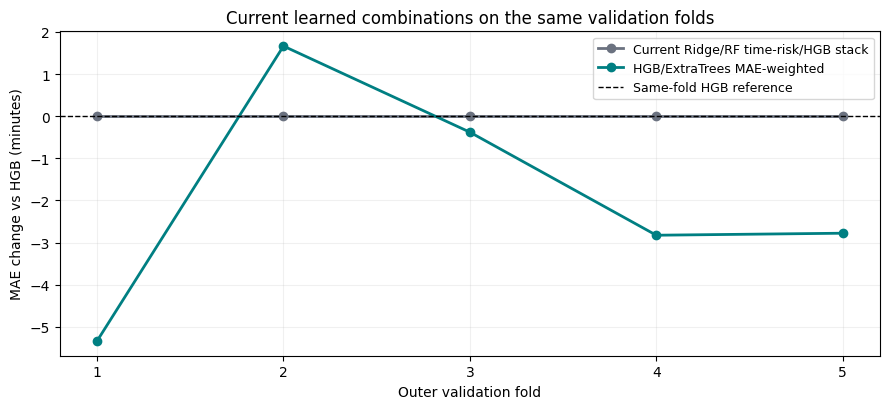

base_model,Current stack: Ridge,Current stack: RF time/risk,Current stack: HGB,ET stack: HGB,ET stack: ExtraTrees
Outer fold,,,,,
1,0.00%,0.00%,100.00%,94.38%,5.62%
2,0.00%,0.00%,100.00%,90.78%,9.22%
3,0.00%,0.00%,100.00%,91.41%,8.59%
4,0.00%,0.00%,100.00%,91.72%,8.28%
5,0.00%,0.00%,100.00%,88.76%,11.24%


ExtraTrees receives **5.62%–11.24%** and HGB **88.76%–94.38%**. The current three-model stack assigns RF **0.00%–0.00%** and HGB **100.00%–100.00%**. A nonzero secondary weight alone does not establish practical usefulness.

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.2))
for name, label, color in [("stack_three_rf_risk", "Current Ridge/RF time-risk/HGB stack", "#6b7280"),
                           ("stack_hgb_extra_trees", "HGB/ExtraTrees MAE-weighted", "#007f82")]:
    delta = (fold_mae[name] - fold_mae.hgb) * 1440
    ax.plot(delta.index, delta, marker="o", linewidth=2, label=label, color=color)
ax.axhline(0, color="black", linewidth=1, linestyle="--", label="Same-fold HGB reference")
ax.set(xlabel="Outer validation fold", ylabel="MAE change vs HGB (minutes)",
       title="Current learned combinations on the same validation folds")
ax.set_xticks(fold_mae.index)
ax.grid(alpha=.18)
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

current_weights = upgrade["tables"]["weights"].query("model == 'stack_three_rf_risk'").pivot(
    index="outer_fold", columns="base_model", values="weight")
new_weights = followup["tables"]["weights"].query("model == 'stack_hgb_extra_trees'").pivot(
    index="outer_fold", columns="base_model", values="weight")
np.testing.assert_allclose(current_weights.sum(axis=1), 1., rtol=0, atol=1e-12)
np.testing.assert_allclose(new_weights.sum(axis=1), 1., rtol=0, atol=1e-12)
weight_table = pd.concat([
    current_weights[["ridge_tuned", "rf_time_risk", "hgb"]].rename(columns={"ridge_tuned": "Current stack: Ridge",
        "rf_time_risk": "Current stack: RF time/risk", "hgb": "Current stack: HGB"}),
    new_weights[["hgb", "extra_trees"]].rename(columns={"hgb": "ET stack: HGB", "extra_trees": "ET stack: ExtraTrees"})], axis=1) * 100
weight_table.index.name = "Outer fold"
display(formatted_table(weight_table, "{:.2f}%"))
display(Markdown(
    f"ExtraTrees receives **{100 * new_weights.extra_trees.min():.2f}%–{100 * new_weights.extra_trees.max():.2f}%** "
    f"and HGB **{100 * new_weights.hgb.min():.2f}%–{100 * new_weights.hgb.max():.2f}%**. "
    f"The current three-model stack assigns RF **{100 * current_weights.rf_time_risk.min():.2f}%–{100 * current_weights.rf_time_risk.max():.2f}%** "
    f"and HGB **{100 * current_weights.hgb.min():.2f}%–{100 * current_weights.hgb.max():.2f}%**. "
    "A nonzero secondary weight alone does not establish practical usefulness."))


## Appendix A — All random-split ensemble candidates

This compact table contains **14 unique combinations**: eight earlier candidates (fixed/tuned × two/three base models × equal mean/MAE weights), four follow-up candidates (RF/ExtraTrees × equal mean/MAE weights), and the current three-model mean/stack with RF time/risk. The previous tuned three-model stack appears once as a historical comparison. Standalone models are references outside that count. Different candidates may reproduce HGB exactly when their secondary weights are zero.

Historical RF in the earlier fixed/tuned combinations uses the **original target**; the follow-up RF uses fixed **log-target F1 without time/risk**. Those rows retain their original names and scores. The current RF is exclusively **log-target F1 + time/risk**.


In [6]:
appendix = ensembles[["label", "mean_fold_MAE_days", "mean_fold_RMSE_days", "MAE_change_vs_HGB_days"]].copy()
appendix["Experiment"] = (["Nested tuning (historical)"] * len(nested_ids)
                          + ["Follow-up"] * len(followup_ids) + ["RF replacement"] * len(upgrade_ids))
appendix["MAE change vs HGB (minutes)"] = appendix.pop("MAE_change_vs_HGB_days") * 1440
appendix = appendix.rename(columns={"label": "Combination", "mean_fold_MAE_days": "Mean MAE (days)",
                                    "mean_fold_RMSE_days": "Mean RMSE (days)"})
appendix = appendix[["Experiment", "Combination", "Mean MAE (days)", "Mean RMSE (days)",
                     "MAE change vs HGB (minutes)"]].reset_index(drop=True)
appendix.index = pd.RangeIndex(1, len(appendix) + 1, name="Candidate")
display(formatted_table(appendix, {"Mean MAE (days)": "{:.6f}", "Mean RMSE (days)": "{:.6f}",
                               "MAE change vs HGB (minutes)": "{:+.2f}"}))
display(Markdown(f"Standalone HGB reference (excluded from the 14): **{fc.loc['hgb', 'mean_fold_MAE_days']:.6f} days MAE**, "
                 f"**{fc.loc['hgb', 'mean_fold_RMSE_days']:.6f} days RMSE**."))
display(Markdown(f"The current three-model equal mean has MAE **{uc.loc['mean_three_rf_risk', 'mean_fold_MAE_days']:.6f} days**, "
                 "higher than HGB in every outer fold. Learning constrained MAE weights avoids that deterioration "
                 "by assigning the full weight to HGB."))
rf_weights = followup["tables"]["weights"].query("model == 'stack_hgb_rf_log'")
assert rf_weights.loc[rf_weights.base_model.eq("rf_log"), "weight"].eq(0).all()
assert rf_weights.loc[rf_weights.base_model.eq("hgb"), "weight"].eq(1).all()
display(Markdown(
    "The historical follow-up HGB/log-target F1 RF weighted combination assigns **100% to HGB in every fold**. "
    "Both follow-up 50/50 averages increase MAE. "
    f"Standalone ExtraTrees has MAE **{fc.loc['extra_trees', 'mean_fold_MAE_days']:.6f} days**, "
    f"with outer residual correlation **{fc.loc['extra_trees', 'residual_correlation_vs_HGB']:.3f}** against HGB. "
    "The high correlation is descriptive; the paired outer-fold scores assess whether its contribution helps."))


,Experiment,Combination,Mean MAE (days),Mean RMSE (days),MAE change vs HGB (minutes)
Candidate,,,,,
1,Nested tuning (historical),Fixed Ridge + forest: mean,4.841101,7.972390,+868.73
2,Nested tuning (historical),Fixed Ridge + forest: MAE stack,4.799663,7.933755,+809.06
3,Nested tuning (historical),Fixed Ridge + forest + HGB: mean,4.542078,7.799712,+438.14
4,Nested tuning (historical),Fixed Ridge + forest + HGB: MAE stack,4.237815,7.745040,+0.00
5,Nested tuning (historical),Tuned Ridge + forest: mean,4.663172,7.779962,+612.51
6,Nested tuning (historical),Tuned Ridge + forest: MAE stack,4.596394,7.730482,+516.35
7,Nested tuning (historical),Tuned Ridge + forest + HGB: mean,4.444073,7.694825,+297.01
8,Nested tuning (historical),Tuned Ridge + forest + HGB: MAE stack,4.237396,7.738271,-0.60
9,Follow-up,HGB + log-target RF: 50/50 average,4.326299,7.810019,+127.42


Standalone HGB reference (excluded from the 14): **4.237815 days MAE**, **7.745040 days RMSE**.

The current three-model equal mean has MAE **4.396924 days**, higher than HGB in every outer fold. Learning constrained MAE weights avoids that deterioration by assigning the full weight to HGB.

The historical follow-up HGB/log-target F1 RF weighted combination assigns **100% to HGB in every fold**. Both follow-up 50/50 averages increase MAE. Standalone ExtraTrees has MAE **4.415865 days**, with outer residual correlation **0.974** against HGB. The high correlation is descriptive; the paired outer-fold scores assess whether its contribution helps.

## Appendix B — Historical tuning and RF audit

The earlier search covers **12 Ridge candidates** (alpha 100/1,000/10,000 × original/log inputs × F0/F1_time) and **six original-target RF candidates** (three depth/leaf/feature-fraction settings × F0/F1_time). RF settings are (24, 10, 0.8), (unrestricted, 5, 0.8), and (16, 20, 0.6); all use 100 trees, bootstrap fraction 0.8, and seed 33. The fixed controls use F0: Ridge has log inputs and alpha 1,000; RF uses the first tree setting. F0 is the original baseline input set.

All five outer partitions select **original-target RF, F1_time, depth 24, leaf 10, feature fraction 0.8**. Tree settings match the fixed control, so this bounded comparison's RF improvement accompanies the feature-pack change. It does not isolate any one feature's effect. Ridge selects F1_time and alpha 100 throughout, with log inputs in four folds and original inputs in one.

The historical follow-up's **fixed log-target RF F1** uses the same tree settings, 100 trees, bootstrap fraction 0.8, and seed 33, but fits `log1p(y)` and returns `expm1` predictions. It has neither the time block nor learned risk feature. Its zero combination weight describes that recorded route only; the current time/risk RF is now evaluated directly above.


In [7]:
tuning_rows = []
for label, fixed, tuned in [("Ridge", "ridge_fixed", "ridge_tuned"),
                             ("RF (original target)", "forest_fixed", "forest_tuned"),
                             ("Ridge + RF MAE stack", "stack_two_fixed", "stack_two_tuned"),
                             ("Ridge + RF + HGB MAE stack", "stack_three_fixed", "stack_three_tuned")]:
    before, after = nc.loc[fixed, "mean_fold_MAE_days"], nc.loc[tuned, "mean_fold_MAE_days"]
    tuning_rows.append({"Model": label, "Fixed MAE": before, "Tuned MAE": after,
                        "Tuned minus fixed (days)": after - before})
display(formatted_table(pd.DataFrame(tuning_rows).set_index("Model"), "{:.6f}"))

# The replacement reproduces the published RF specification on the matching outer folds.
published_path = REGRESSION / "results/report_supplement/tables/cv_fold_metrics.csv"
published_folds = pd.read_csv(published_path)
published_rf = published_folds.loc[published_folds.model.eq("RF + time/risk")]
assert len(published_rf) == published_rf.fold.nunique() == outer_folds
assert published_rf.n.sum() == followup["summary"]["train_n"]
np.testing.assert_allclose(published_rf.MAE_days.mean(), uc.loc["rf_time_risk", "mean_fold_MAE_days"],
                           rtol=0, atol=1e-12)
display(Markdown(
    f"Historical log-target F1 RF has mean MAE **{fc.loc['rf_log', 'mean_fold_MAE_days']:.6f} days**. "
    f"The current **log-target RF + time/risk** reproduces the published mean CV MAE of "
    f"**{published_rf.MAE_days.mean():.6f} days** and is tested in the current three-model combinations. "
    "The immutable single-model tables in the [integrated report](delivery_regression_complete.ipynb) "
    "retain earlier variants to document development; they do not introduce multiple current RF definitions."))


,Fixed MAE,Tuned MAE,Tuned minus fixed (days)
Model,,,
Ridge,5.035208,4.921914,-0.113294
RF (original target),4.806196,4.600224,-0.205972
Ridge + RF MAE stack,4.799663,4.596394,-0.203269
Ridge + RF + HGB MAE stack,4.237815,4.237396,-0.000419


Historical log-target F1 RF has mean MAE **4.538555 days**. The current **log-target RF + time/risk** reproduces the published mean CV MAE of **4.415217 days** and is tested in the current three-model combinations. The immutable single-model tables in the [integrated report](delivery_regression_complete.ipynb) retain earlier variants to document development; they do not introduce multiple current RF definitions.

Detailed selection evidence is available in the [earlier selected candidates](../stacking/nested_tuning/results/tables/selected_candidates.csv), [inner candidate scores](../stacking/nested_tuning/results/tables/inner_candidate_metrics.csv), [follow-up target selections](../stacking/ensemble_followup/results/tables/selections.csv), and [current stack specifications](../stacking/rf_risk_upgrade/results/tables/selected_candidates.csv). Inner scores describe selection evidence, not independent validation performance.

## Appendix C — Reproduction and historical context

Use Python 3.12 and [the pinned dependencies](../stacking/requirements.txt). The [nested tuning guide](../stacking/nested_tuning/README.md) documents its prerequisite HGB reference, model runners and independent verifier. The [follow-up guide](../stacking/ensemble_followup/README.md) documents the historical RF/ExtraTrees runners, and the [RF replacement guide](../stacking/rf_risk_upgrade/README.md) documents the fixed time/risk RF and current combinations. Rebuilding the older HGB reference has its own scope, including existing holdout metrics; all three ensemble experiments consume training artifacts only. Private fitted models and order-level predictions remain under ignored `stacking/runs/` directories.

To execute this notebook against the saved experiment results, run from **`Phase 2/Final Notebooks/Regression`**, using the Python environment with the pinned dependencies installed:

```bash
python scripts/run_notebook.py notebooks/tuned_stacking_comparison.ipynb
```

Notebook execution checks saved public artifact hashes, protocol hashes, reference parity and candidate counts. Full model replay and weight-optimality verification require the local training artifacts and the experiment-specific verifiers; displaying the notebook does not rerun those audits.

The earlier [temporal-split ensemble report](../../../Regression%20Work/historical_temporal/notebooks/ensemble_comparison.ipynb) is historical context. It uses a different evaluation design and is not ranked together with these random-split results. A future-performance claim needs a later evaluation cohort with features available at prediction time.
